# WasteSort reproducible training

This notebook downloads real TrashNet images, audits them, trains the four proposal models plus introductory exercises and a weighting ablation, and saves actual results.

In Colab choose **Runtime → Change runtime type → GPU**, then **Runtime → Run all**. GPU availability is managed by Colab. Training can run on CPU but takes longer.

Every execution creates a new experiment folder. The published study is never overwritten. Scores may vary across hardware and library builds; the dataset split and source hashes are recorded. Group members must inspect the dataset and understand the results before submission.


In [1]:
from pathlib import Path
import os, shutil, subprocess, sys, tempfile
workspace = Path(tempfile.mkdtemp(prefix="wastesort-"))
source = workspace / "source"
subprocess.run(["git", "clone", "https://github.com/haerinfan/wastesort.git", str(source)], check=True)
source_commit = subprocess.check_output(["git", "-C", str(source), "rev-parse", "HEAD"], text=True).strip()
print("Source commit:", source_commit)
print("Workspace:", workspace)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(source / "requirements.txt")], check=True)


Source commit: ba00c8ee3b03c2f21e5128fda92d1ed4b1334b52
Workspace: /tmp/wastesort-5ow_jql_


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '-r', '/tmp/wastesort-5ow_jql_/source/requirements.txt'], returncode=0)

## Prepare a fresh experiment
The source archive and split are checked against the published provenance. Conflicting exact duplicates are excluded; candidate near-duplicates stay in the same partition.

In [2]:
run = workspace / "experiment"
run.mkdir()
(run / "data").mkdir()
(run / "reports").mkdir()
shutil.copyfile(source / "protocol.json", run / "protocol.json")
for relative in ["data/provenance.json", "data/splits.csv", "reports/data_audit.json"]:
    shutil.copyfile(source / relative, run / relative)
env = dict(os.environ, WASTESORT_ROOT=str(run))
def execute(module):
    subprocess.run([sys.executable, "-u", "-m", "wastesort." + module], cwd=source, env=env, check=True)
execute("data")
(run / "reports/source_commit.txt").write_text(source_commit)


40

,label,test,train,validation
0,cardboard,59,287,57
1,glass,73,352,73
2,metal,63,281,65
3,paper,93,411,90
4,plastic,70,343,67
5,trash,18,100,19


,path,reason,retained
0,data/raw/glass/glass115.jpg,conflicting_labels_for_identical_pixels,NaN
1,data/raw/metal/metal91.jpg,conflicting_labels_for_identical_pixels,NaN
2,data/raw/glass/glass176.jpg,conflicting_labels_for_identical_pixels,NaN
3,data/raw/plastic/plastic152.jpg,conflicting_labels_for_identical_pixels,NaN
4,data/raw/glass/glass389.jpg,conflicting_labels_for_identical_pixels,NaN
5,data/raw/plastic/plastic332.jpg,conflicting_labels_for_identical_pixels,NaN


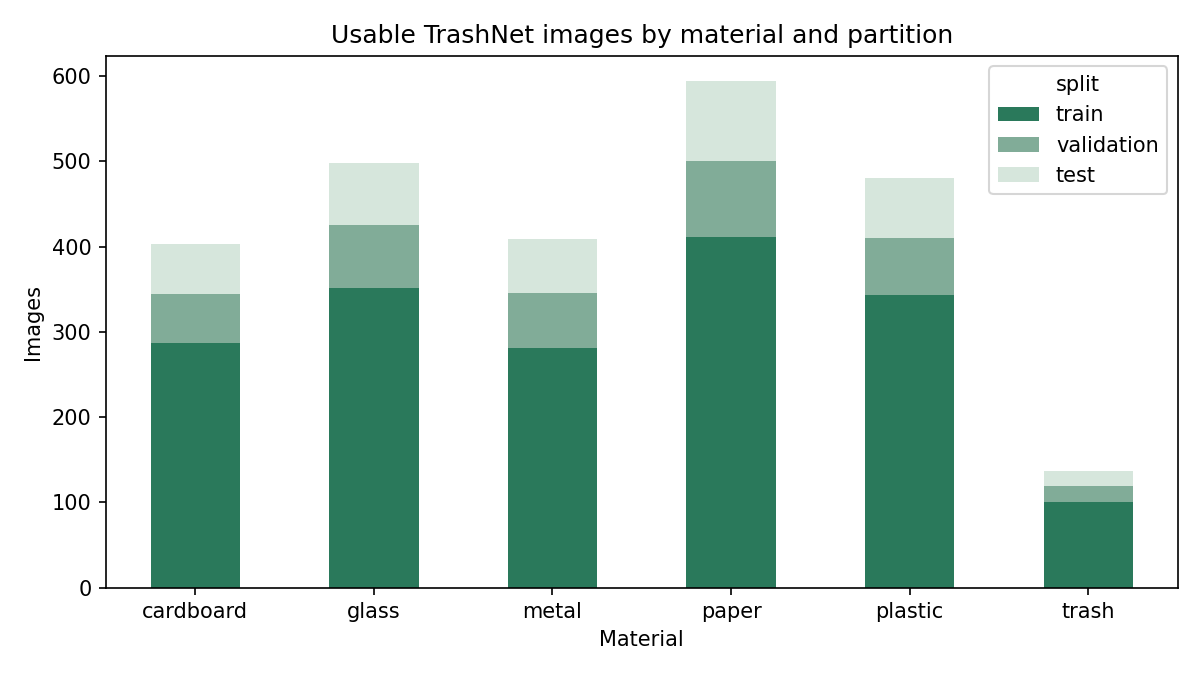

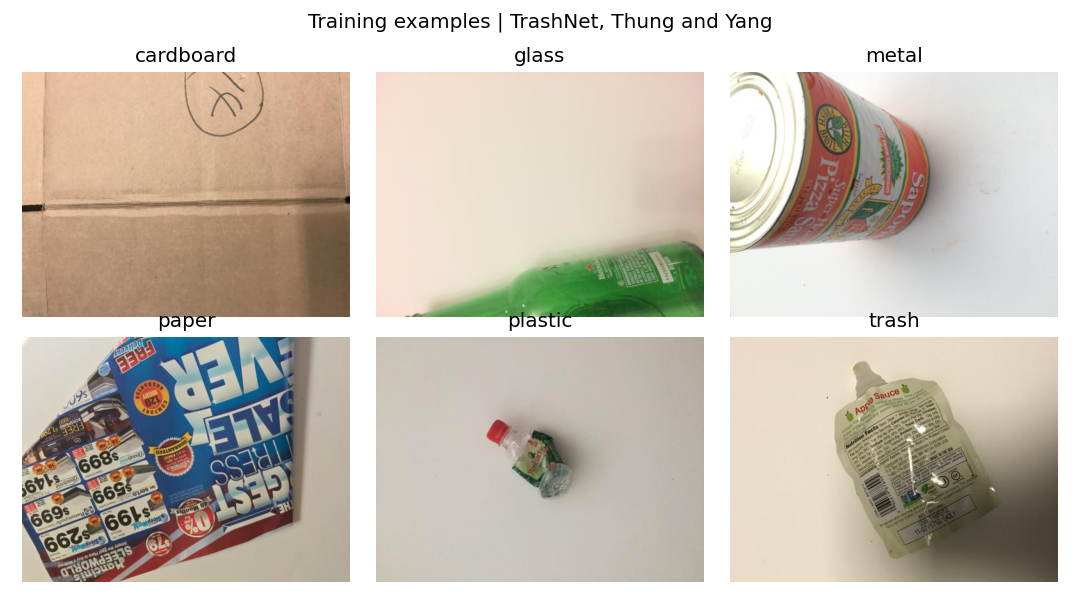

In [3]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv(run / "reports/split_counts.csv"))
display(pd.read_csv(run / "reports/excluded.csv"))
execute("figures")
display(Image(filename=str(run / "reports/class_distribution.png")))
display(Image(filename=str(run / "reports/training_examples.png")))


## Train on training data and select using validation only

Primary models: HOG + SVM, HOG + Random Forest, small CNN, MobileNetV2.
Auxiliary experiments: KNN, Decision Tree and weighted small CNN.

The configuration in `protocol.json` is fixed before this cell. Do not edit settings after seeing the final test results and still call that test unseen.

In [4]:
execute("train")
import json
deployment = json.loads((run / "models/deployment.json").read_text())
print("Model selected BEFORE test evaluation:", deployment["model_id"])
print("Validation macro F1:", deployment["validation_macro_f1"])


Model selected BEFORE test evaluation: mobilenet
Validation macro F1: 0.8474362310329003


## Final held-out evaluation
This runs once after model selection. Bootstrap intervals are descriptive and conditional on a single fitted run. They do not establish campus performance or variation across training seeds.

,model,role,validation_macro_f1,test_accuracy,test_macro_f1,trash_recall,training_seconds,model_size_mb,inference_ms_mean
0,svm,primary,0.606166,0.659574,0.635168,0.388889,6.743672,12.782696,5.056837
1,random_forest,primary,0.559411,0.635638,0.602211,0.333333,28.224308,7.318188,76.787110
2,cnn,primary,0.585250,0.558511,0.539926,0.611111,57.420585,0.116170,9.892923
3,mobilenet,primary,0.847436,0.845745,0.812199,0.555556,74.884459,8.734019,38.195589
4,cnn_weighted,ablation,0.596369,0.566489,0.568920,0.777778,86.498034,0.116717,9.619851


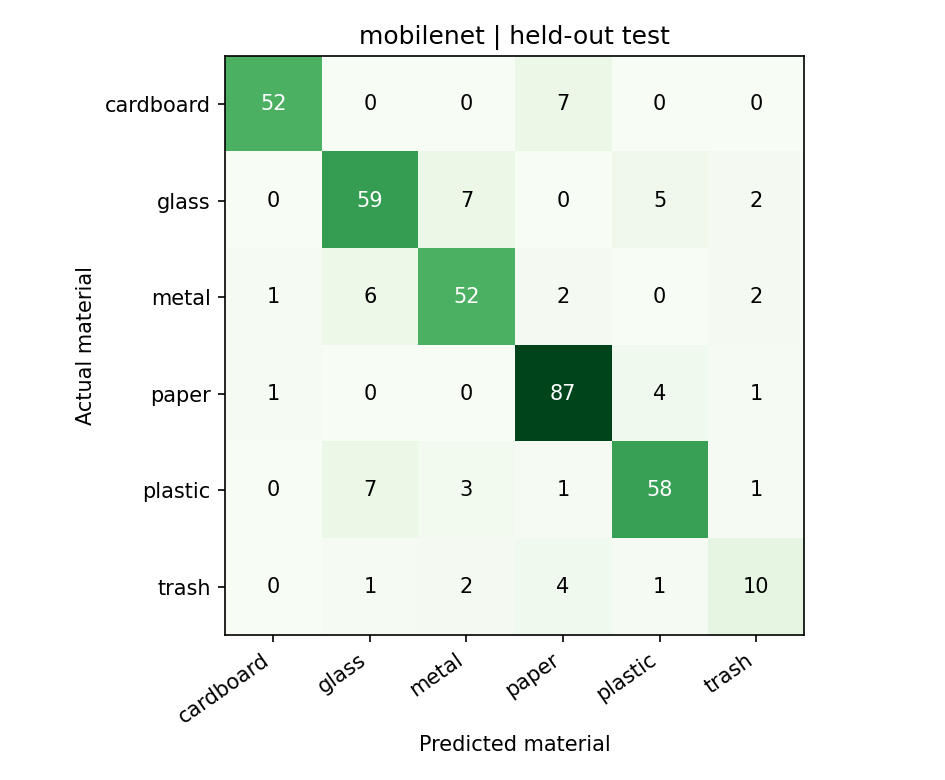

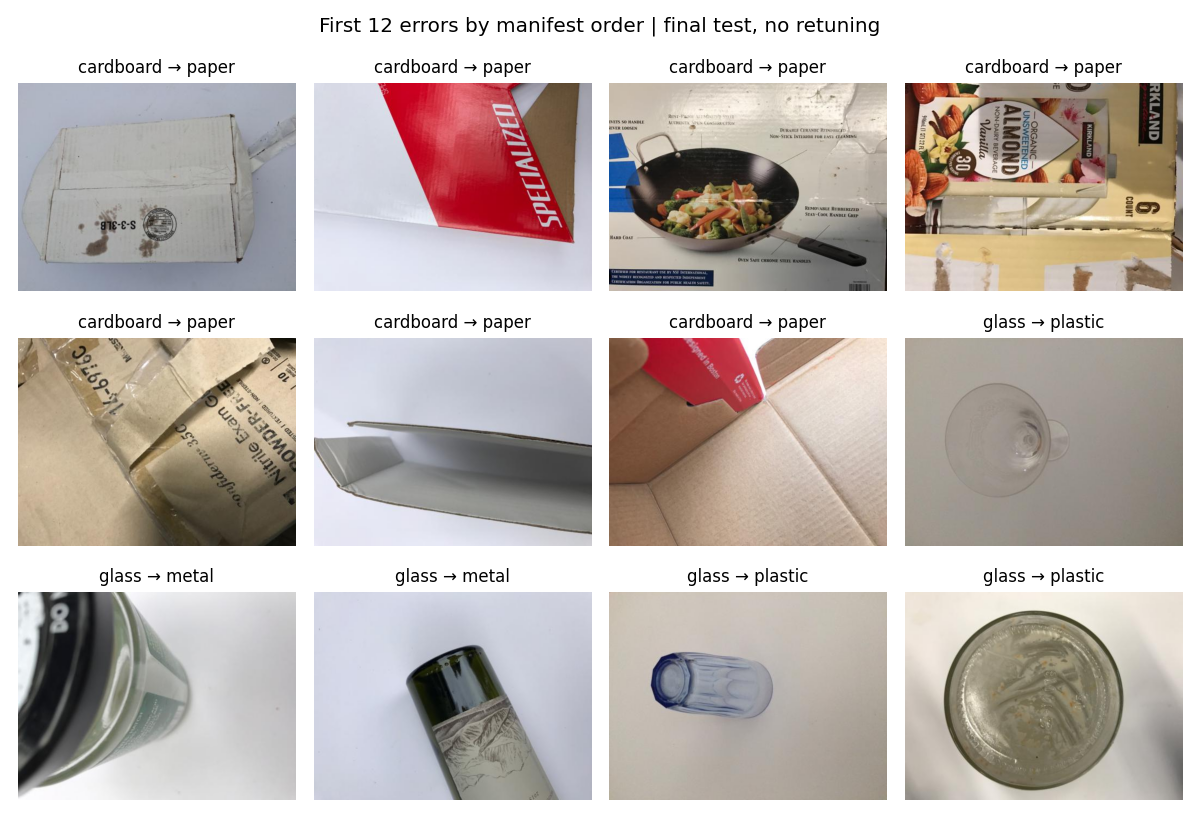

{
  "resamples": 2000,
  "unit": "perceptual-hash candidate group",
  "macro_f1_95_percent_intervals": {
    "svm": [
      0.5709879876146716,
      0.688616744059204
    ],
    "random_forest": [
      0.5376266630235506,
      0.6567361484576913
    ],
    "cnn": [
      0.48318005813672377,
      0.5903304691277796
    ],
    "mobilenet": [
      0.7624591924675445,
      0.8559833149822197
    ],
    "cnn_weighted": [
      0.5155263877873968,
      0.6159447227677879
    ]
  },
  "paired_difference_95_percent_intervals": {
    "mobilenet_minus_cnn_macro_f1": [
      0.21245904506910523,
      0.34137876683010965
    ],
    "cnn_weighted_minus_cnn_macro_f1": [
      -0.014274361958771572,
      0.07423218509470533
    ],
    "cnn_weighted_minus_cnn_trash_recall": [
      -0.0714285714285714,
      0.4
    ]
  },
  "interpretation": "Descriptive conditional intervals for one fitted run; no formal significance claims."
}
Separate regression exercise:
{
  "purpose": "Separate numeric

In [5]:
execute("evaluate")
execute("exercises")
execute("figures")
display(pd.read_csv(run / "reports/comparison.csv"))
display(Image(filename=str(run / f"reports/{deployment['model_id']}_confusion.png")))
display(Image(filename=str(run / "reports/error_examples.png")))
print((run / "reports/uncertainty.json").read_text())
print("Separate regression exercise:")
print((run / "reports/regression_exercise.json").read_text())


## Save the experiment evidence
The exported ZIP contains reports, checkpoints, protocol and manifests. Raw photographs remain available through the original download source. The notebook itself must also be saved with its outputs for your contribution record.

In [6]:
export = workspace / "export"
export.mkdir()
for folder in ["reports", "models"]:
    shutil.copytree(run / folder, export / folder, ignore=shutil.ignore_patterns("audit_images"))
(export / "data").mkdir()
for relative in ["data/provenance.json", "data/splits.csv", "protocol.json"]:
    shutil.copyfile(run / relative, export / relative)
archive = shutil.make_archive(str(workspace / "WasteSort_experiment"), "zip", export)
print("Experiment archive:", archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print("Download the ZIP from the notebook file browser.")


Experiment archive: /tmp/wastesort-5ow_jql_/WasteSort_experiment.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Group review

- Verify the dataset audit, candidate duplicates, reference list and actual member contributions.
- Explain validation versus test, macro F1, minority-class recall and the confusion matrix.
- Confirm campus rules before adding bin instructions.
- Report campus photos separately from the TrashNet benchmark.

Dataset: [TrashNet by Gary Thung and Mindy Yang](https://github.com/garythung/trashnet).
AI assisted code and experiment execution; human verification remains required.
